<a href="https://colab.research.google.com/github/mariasalesss/modelagemcomputacional/blob/main/segmentacao_pluma_sam_revap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção e segmentação de uma pluma com SAM
**Modelagem Computacional – Profa Raquel Lobosco**
Aluna: Maria Fernanda de Sales Reis



## 1. Instalação e modelo

In [19]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git opencv-python-headless
!wget -nc -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

  Preparing metadata (setup.py) ... done


In [20]:
import numpy as np, cv2, torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from segment_anything import sam_model_registry, SamPredictor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth").to(device)
predictor = SamPredictor(sam)

Dispositivo: cuda


## 2. Imagem da pluma

Saving Captura de tela 2026-10-19 155007.png to Captura de tela 2026-10-19 155007 (2).png
Tamanho: 600 x 547


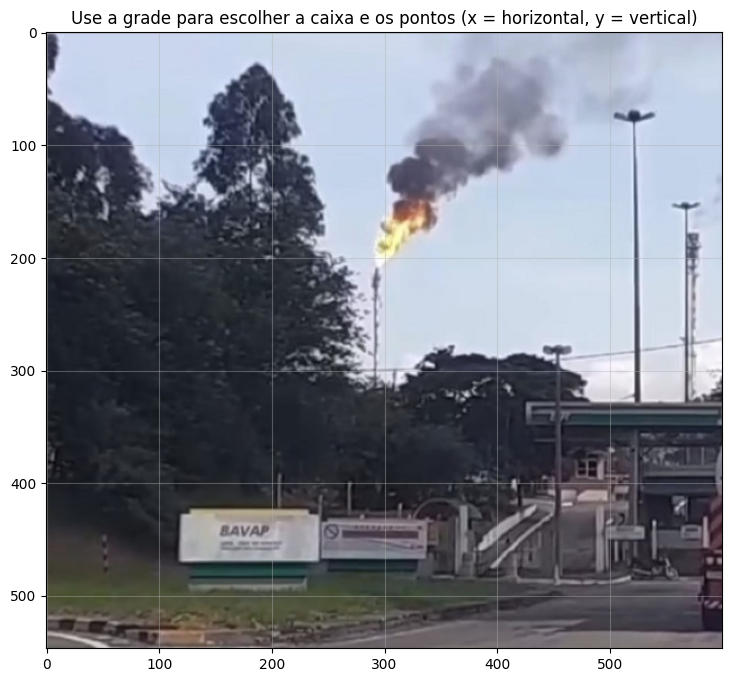

In [21]:
from google.colab import files
up = files.upload()
IMAGE_PATH = list(up.keys())[0]
image = cv2.cvtColor(cv2.imread(IMAGE_PATH), cv2.COLOR_BGR2RGB)

# reduz imagens muito grandes (as coordenadas abaixo valem para esta versão)
MAX_SIDE = 1280
h, w = image.shape[:2]
if max(h, w) > MAX_SIDE:
    s = MAX_SIDE / max(h, w)
    image = cv2.resize(image, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
h, w = image.shape[:2]
print("Tamanho:", w, "x", h)

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.xticks(range(0, w, 100)); plt.yticks(range(0, h, 100))
plt.grid(True, alpha=0.4)
plt.title("Use a grade para escolher a caixa e os pontos (x = horizontal, y = vertical)")
plt.show()

## 3. Prompts
- **BOX**: `[290, 15, 470, 205]` em volta da pluma.
- **POS**: pontos `[[380, 100], [340, 135], [430, 85]]` em cima da fumaça.
- **NEG**: pontos `[[400, 230], [480, 150], [292, 270], [180, 110]]` em céu, nuvens, prédios ou chaminé (o que NÃO é pluma).


In [22]:
BOX = [290, 15, 470, 205]
POS = [[380, 100], [340, 135], [430, 85]]
NEG = [[400, 230], [480, 150], [292, 270], [180, 110]]

predictor.set_image(image)

def run_sam(box=None, pos=(), neg=()):
    pts = list(pos) + list(neg)
    lbl = [1]*len(pos) + [0]*len(neg)
    masks, scores, _ = predictor.predict(
        point_coords=np.array(pts) if pts else None,
        point_labels=np.array(lbl) if pts else None,
        box=np.array(box) if box is not None else None,
        multimask_output=True)
    i = int(np.argmax(scores))
    return masks[i], float(scores[i])

def show_triplet(mask, title, box=None, pos=(), neg=()):
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    ax[0].imshow(image); ax[0].set_title("Original")
    ax[1].imshow(mask, cmap="gray"); ax[1].set_title("Máscara binária")
    ov = image.astype(float).copy()
    ov[mask] = 0.5*ov[mask] + 0.5*np.array([255, 0, 0])
    ax[2].imshow(ov.astype(np.uint8)); ax[2].set_title("Máscara sobreposta")
    for a in (ax[0], ax[2]):
        if box is not None:
            a.add_patch(patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                          fill=False, edgecolor="cyan", linewidth=2))
        if len(pos): a.scatter(*zip(*pos), c="lime", s=120, marker="*", edgecolor="k")
        if len(neg): a.scatter(*zip(*neg), c="yellow", s=100, marker="X", edgecolor="k")
    for a in ax: a.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.show()

## 4. Quatro configurações de prompt

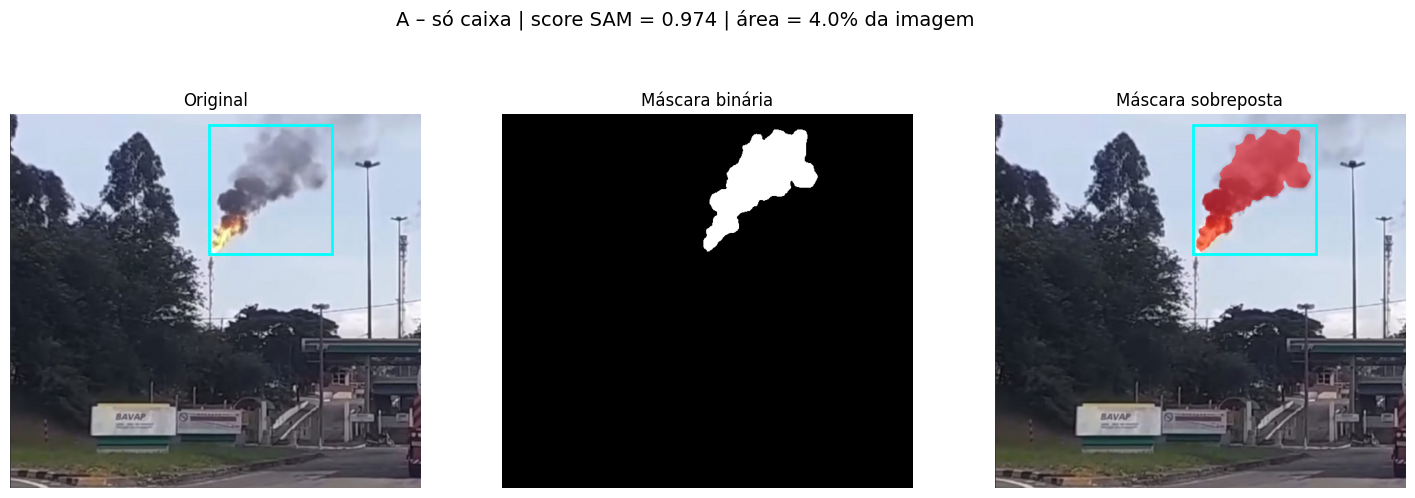

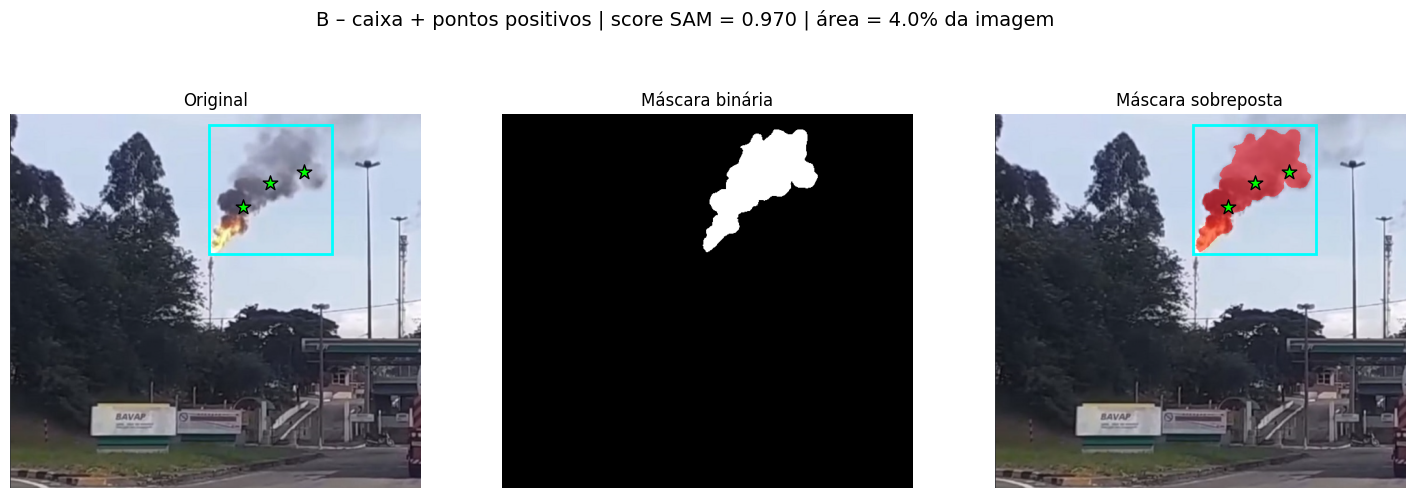

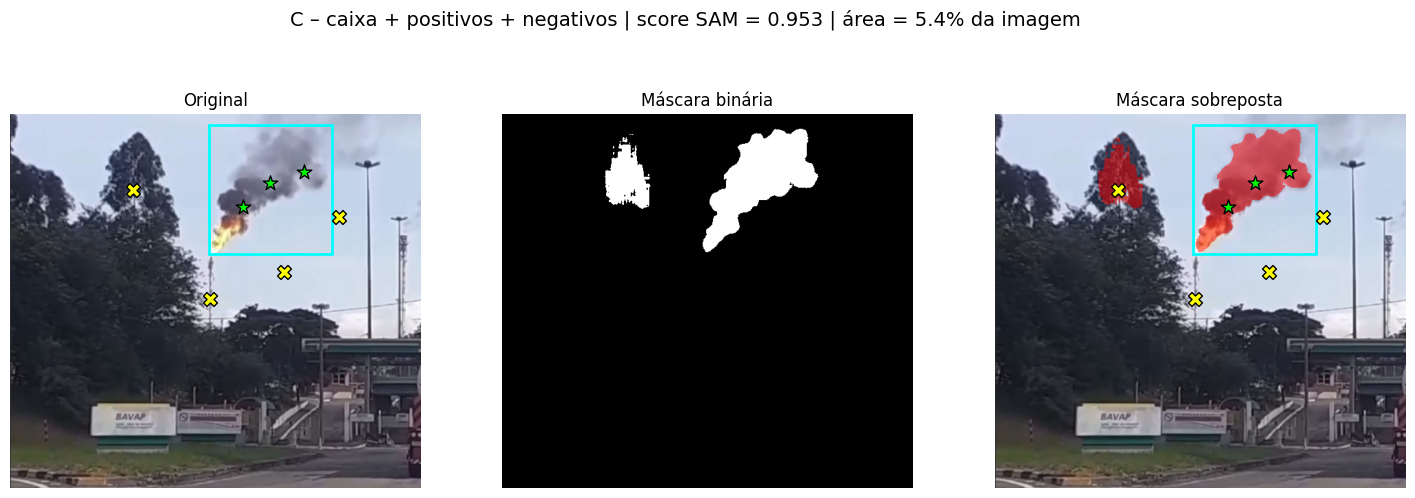

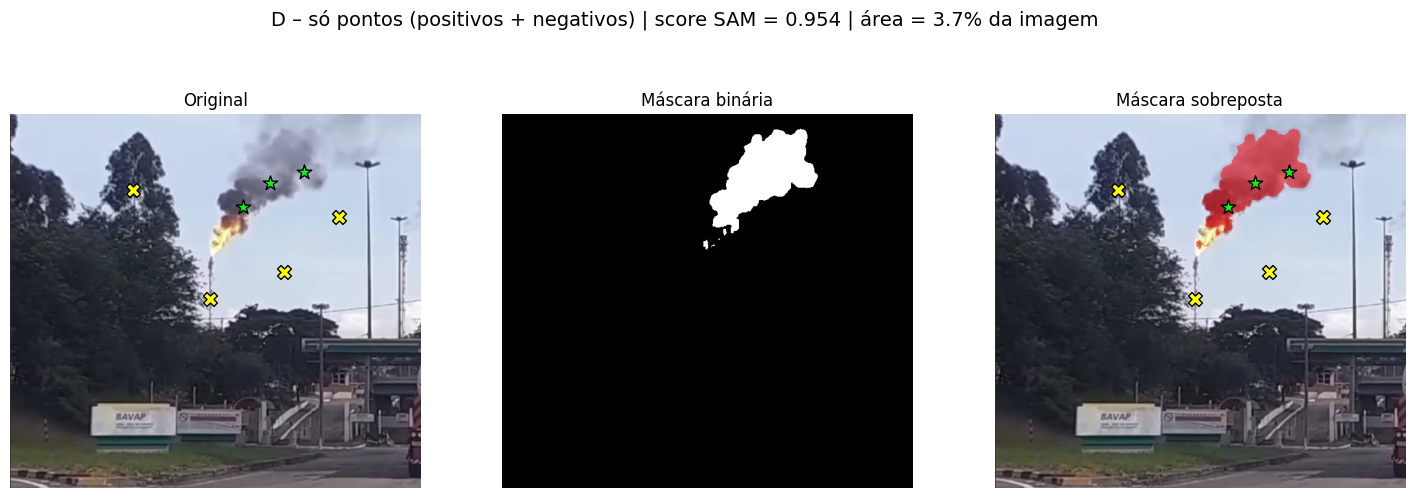

In [23]:
CONFIGS = {
    "A – só caixa":                         dict(box=BOX, pos=(),  neg=()),
    "B – caixa + pontos positivos":         dict(box=BOX, pos=POS, neg=()),
    "C – caixa + positivos + negativos":    dict(box=BOX, pos=POS, neg=NEG),
    "D – só pontos (positivos + negativos)": dict(box=None, pos=POS, neg=NEG),
}
results = {}
for name, cfg in CONFIGS.items():
    mask, score = run_sam(**cfg)
    results[name] = mask
    pct = 100 * mask.sum() / mask.size
    show_triplet(mask, f"{name} | score SAM = {score:.3f} | área = {pct:.1f}% da imagem", **cfg)

## 5. Comparação quantitativa entre configurações

Área da máscara (% da imagem):
  A – só caixa                                 3.96%
  B – caixa + pontos positivos                 3.98%
  C – caixa + positivos + negativos            5.36%
  D – só pontos (positivos + negativos)        3.68%

IoU entre configurações:


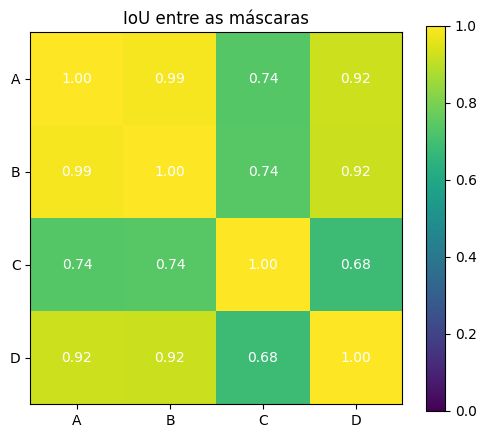

In [24]:
names = list(results)
def iou(a, b): return (a & b).sum() / max((a | b).sum(), 1)

print("Área da máscara (% da imagem):")
for n in names: print(f"  {n:42s} {100*results[n].sum()/results[n].size:6.2f}%")

print("\nIoU entre configurações:")
M = np.array([[iou(results[a], results[b]) for b in names] for a in names])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
ax.set_xticklabels([n[0] for n in names]); ax.set_yticklabels([n[0] for n in names])
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", color="w")
plt.colorbar(im); plt.title("IoU entre as máscaras"); plt.show()

## 6. Melhoria: pós-processamento da máscara
Mantém apenas a maior região conectada, remove ruído (abertura) e fecha buracos (fechamento). Também recorta a máscara à caixa, já que a pluma não pode estar fora dela.

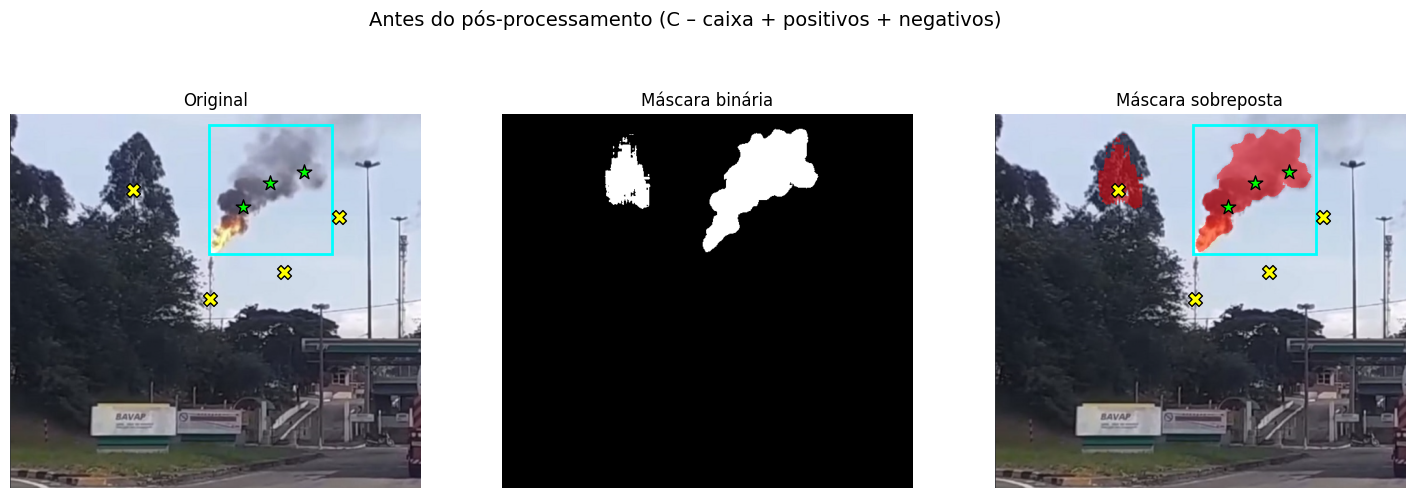

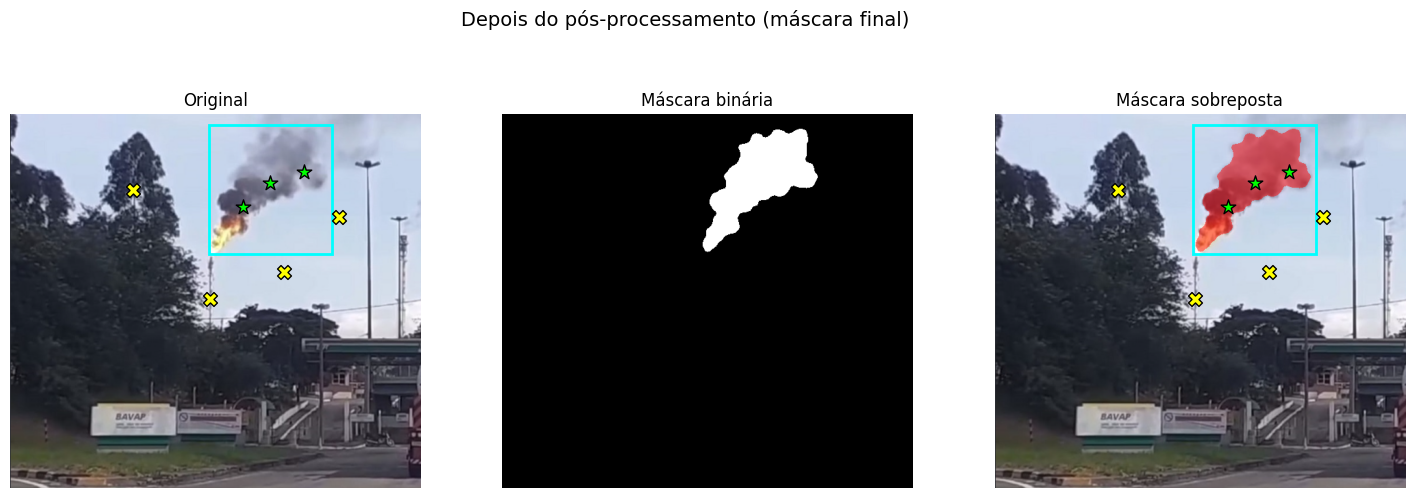

Área antes: 5.36% | depois: 4.09% | IoU antes×depois: 0.757


In [25]:
def refine(mask, box=None, k=9):
    m = mask.astype(np.uint8)
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ker)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ker)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m)
    if n > 1:
        m = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    if box is not None:
        keep = np.zeros_like(m)
        keep[int(box[1]):int(box[3]), int(box[0]):int(box[2])] = 1
        m = m * keep
    return m.astype(bool)

best_name = "C – caixa + positivos + negativos"
raw = results[best_name]
final = refine(raw, box=BOX)
show_triplet(raw,   f"Antes do pós-processamento ({best_name})", box=BOX, pos=POS, neg=NEG)
show_triplet(final, "Depois do pós-processamento (máscara final)", box=BOX, pos=POS, neg=NEG)
print(f"Área antes: {100*raw.sum()/raw.size:.2f}% | depois: {100*final.sum()/final.size:.2f}% | IoU antes×depois: {iou(raw, final):.3f}")

## 7. Medidas da imagem para a análise de dificuldades

In [26]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY).astype(float)
hsv  = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(float)

def stats(region, nome):
    print(f"{nome:28s} brilho médio={gray[region].mean():6.1f} | contraste (desvio)={gray[region].std():5.1f} | saturação média={hsv[...,1][region].mean():5.1f}")

stats(final,  "Pluma (máscara final)")
stats(~final, "Resto da imagem")

CEU = [380, 190, 500, 260]
r = np.zeros_like(final); r[CEU[1]:CEU[3], CEU[0]:CEU[2]] = True
stats(r, "Céu/nuvem (região CEU)")

sep = abs(gray[final].mean() - gray[r].mean()) / (gray[r].std() + 1e-6)
print(f"\nSeparação pluma × céu (diferença de brilho / desvio do céu): {sep:.2f}  (quanto menor, mais difícil separar)")

Pluma (máscara final)        brilho médio= 147.1 | contraste (desvio)= 34.7 | saturação média= 44.1
Resto da imagem              brilho médio= 115.5 | contraste (desvio)= 76.2 | saturação média= 45.3
Céu/nuvem (região CEU)       brilho médio= 217.9 | contraste (desvio)=  2.2 | saturação média= 29.2

Separação pluma × céu (diferença de brilho / desvio do céu): 32.85  (quanto menor, mais difícil separar)


## 8. Análise

**O que observei em cada configuração**

- **A (só caixa):** a máscara pegou a pluma toda, incluindo a chama lá embaixo, e não pegou céu nem prédio. Mas a fumaça mais fraquinha, no canto de cima à direita, ficou de fora. Provavelmente foi porque ela está fora da caixa que eu desenhei e também porque ela é quase da mesma cor do céu.
- **B (caixa + pontos positivos):** ficou praticamente igual à A (IoU = 0,99). Como a caixa já estava bem em volta da pluma, os pontos positivos não mudaram quase nada.
- **C (caixa + positivos + negativos):** a pluma ficou igual, mas apareceu uma mancha na copa de uma árvore, fora da caixa. Eu tinha colocado um ponto negativo ali justamente para isso não acontecer, e mesmo assim o SAM segmentou. Acho que a folhagem escura se parece com a fumaça escura. Nessa configuração a área subiu de 4,0% para 5,4% por causa desse erro, e ela foi a mais diferente das outras (IoU entre 0,68 e 0,74).
- **D (só pontos):** ficou limpa, sem a árvore, mas a chama quase não entrou e sobraram uns pedacinhos soltos na base. Ficou parecida com A e B (IoU = 0,92).

O que me surpreendeu foi que a C, que tinha mais informação, foi a que errou. Então dar mais prompts não garante uma máscara melhor. Também vi que a caixa muda bastante o que o SAM entende como "objeto": com a caixa a chama entra, só com pontos ela fica de fora.

**Melhor configuração:** para a máscara bruta, achei a A a melhor, porque é simples e não tem erro. Para mostrar a melhoria, usei a C, já que ela tinha um erro para corrigir.

**Minha melhoria no código (pós-processamento):** fiz três coisas na máscara da C: suavizei o contorno (abertura e fechamento), fiquei só com a maior região conectada e cortei tudo que estava fora da caixa. A área caiu de 5,36% para 4,09% (IoU antes × depois = 0,757) e a mancha da árvore sumiu. A pluma e a chama continuaram na máscara. A fumaça fraca do topo direito continua de fora, então a máscara final ainda não cobre 100% da pluma.

**O que dificultou a segmentação**

- **Iluminação:** nesta foto ela ajudou. O céu está claro e bem uniforme (brilho médio 217,9 e desvio 2,2).
- **Contraste:** a pluma é mais escura que o céu (brilho médio 147,1), então a parte densa é fácil de separar. O número de "separação" deu 32,85, mas ele ficou alto só porque o pedaço de céu que escolhi é muito uniforme. Ele não vale para as bordas da fumaça.
- **A pluma não é uniforme:** o desvio de brilho dentro da máscara é 34,7. Ela tem miolo escuro, chama laranja e uma borda clara e transparente. Por isso a chama dependeu do prompt e a borda não foi pega.
- **Fumaça parecida com outras coisas:** a saturação da pluma (44,1) é quase igual à do resto da imagem (45,3), então a cor não ajudou a separar. O miolo escuro se confunde com as árvores, o que explica o erro da C. E a fumaça fraca se confunde com o céu, como se fosse uma nuvem, o que foi o maior limite.

**Limitações e o que eu faria depois**

- Usei só uma imagem e escolhi a caixa e os pontos na mão, então não dá para dizer que funciona sempre assim.
- Não tenho uma máscara "certa" feita à mão para comparar. A avaliação foi olhando as imagens e comparando as configurações entre si (IoU), não contra um gabarito.
- Para melhorar eu tentaria aumentar a caixa e colocar pontos positivos na fumaça fraca, juntar o SAM com um filtro de brilho/saturação para pegar a borda, e testar o modelo maior (`vit_h`).

